# MW Scan Analysis (Manual Threshold)

Same as hybrid analysis but lets you set atom detection threshold manually
from SPCM count histograms instead of using the experiment threshold.


In [105]:
# Setup (run once)
import sys, os
sys.path.insert(0, r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository")

import numpy as np
import matplotlib.pyplot as plt
import h5py
import glob
import datetime
from pathlib import Path

from analysis.data_loader import load_h5, find_runs, RESULTS_DIR
from analysis.microwave_analysis import fit_scan_result

%matplotlib inline
# --- auto-reload fitting/analysis modules on file edits (no kernel restart needed) ---
%load_ext autoreload
%autoreload 2

plt.rcParams['figure.dpi'] = 120
print(f"Results directory: {RESULTS_DIR}")
print("Setup complete.")

def _scalar(v, default=0.0):
    """Unwrap an HDF5 scalar dataset value to a Python float.

    Handles: plain numbers, bytes, 0-d numpy arrays, 1-element 1-d arrays,
    and any iterable where the last element is the freshest value.
    """
    if v is None:
        return float(default)
    if isinstance(v, (bytes, bytearray)):
        return float(v.decode())
    arr = np.asarray(v)
    if arr.ndim == 0:
        return float(arr)
    if arr.size == 0:
        return float(default)
    return float(arr.flat[-1])


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Results directory: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results
Setup complete.


## 1. List Recent Runs
Re-run this cell to refresh (e.g. after a new experiment finishes).

In [106]:
files = find_runs(format="h5")
if not files:
    print(f"No HDF5 files in {RESULTS_DIR}")
else:
    rows = []
    for f in files[-30:]:
        fname = os.path.basename(f)
        parts = fname.replace(".h5", "").split("-", 1)
        rid = parts[0] if parts else "?"
        exp = parts[1] if len(parts) > 1 else "?"
        folder = str(Path(f).parent.relative_to(RESULTS_DIR))
        dt = datetime.datetime.fromtimestamp(os.path.getmtime(f))
        mode = typ = ""
        try:
            with h5py.File(f, "r") as hf:
                ds = hf.get("datasets")
                if ds is not None:
                    for key in ["mw_scan_mode", "mw_scan_type"]:
                        if key in ds:
                            val = ds[key][()]
                            val = val.decode() if isinstance(val, bytes) else str(val)
                        elif key in ds.attrs:
                            val = ds.attrs[key]
                            val = val.decode() if isinstance(val, bytes) else str(val)
                        else:
                            val = ""
                        if key == "mw_scan_mode": mode = val
                        else: typ = val
        except Exception:
            pass
        rows.append((rid, exp, mode, typ, dt.strftime("%Y-%m-%d"), dt.strftime("%H:%M"), folder))

    print(f"{'RID':>9s}  {'Experiment':<22s}  {'Mode':<12s}  {'Type':<11s}  {'Date':<12s}  {'Time':<6s}  Folder")
    print(f"{'-'*9}  {'-'*22}  {'-'*12}  {'-'*11}  {'-'*12}  {'-'*6}  {'-'*20}")
    for r in reversed(rows):
        print(f"{r[0]:>9s}  {r[1]:<22s}  {r[2]:<12s}  {r[3]:<11s}  {r[4]:<12s}  {r[5]:<6s}  {r[6]}")

      RID  Experiment              Mode          Type         Date          Time    Folder
---------  ----------------------  ------------  -----------  ------------  ------  --------------------
000000531  MicrowaveScan           Time_2ph      time         2026-06-09    16:08   2026-06-09\15
000000529  MicrowaveScan           Freq_2ph      frequency    2026-06-09    15:42   2026-06-09\15
000000527  MicrowaveScan           Time_11       time         2026-06-09    15:15   2026-06-09\14
000000525  MicrowaveScan           Freq_11       frequency    2026-06-09    14:56   2026-06-09\14
000000521  MicrowaveScan           Freq_11       frequency    2026-06-09    14:41   2026-06-09\14
000000519  MicrowaveScan           Freq_01       frequency    2026-06-09    14:20   2026-06-09\14
000000518  MicrowaveScan           Time_01       time         2026-06-09    13:43   2026-06-09\13
000000516  MicrowaveScan           Freq_01       frequency    2026-06-09    13:23   2026-06-09\13
000000511  Microwave

## 2. Select Run
Set `RID` below and run the cell. Use `None` for the latest run.

In [108]:
########################################
RID = None   # <-- set RID here, or None for latest
########################################

if RID is not None:
    pattern = f"{RID:09d}-*.h5"
    matches = glob.glob(str(RESULTS_DIR / "**" / pattern), recursive=True)
    if not matches:
        raise FileNotFoundError(f"No HDF5 for RID {RID} in {RESULTS_DIR}")
    # Pick the latest file -- each incremental save has all data
    filepath = max(matches, key=os.path.getmtime)
    if len(matches) > 1:
        print("Found {} files for RID {}, using latest:".format(len(matches), RID))
        for m in sorted(matches, key=os.path.getmtime):
            sel = "<-- selected" if m == filepath else ""
            print("  {}  {} KB  {}".format(os.path.basename(m), int(os.path.getsize(m)/1024), sel))
else:
    all_files = find_runs(format="h5")
    if not all_files:
        raise FileNotFoundError(f"No HDF5 files in {RESULTS_DIR}")
    filepath = all_files[-1]
    print("(Using latest run)")

print(f"File: {os.path.basename(filepath)}")
print(f"Path: {filepath}")

result = load_h5(filepath)
data = result["data"]
meta = result["metadata"]
archive = result["archive"]

# Extract RID from filename (ARTIQ stores rid at top-level, not in datasets/)
try:
    run_rid = int(os.path.basename(filepath).split("-")[0])
except (ValueError, IndexError):
    run_rid = "?"
data["rid"] = run_rid
print(f"RID: {run_rid}")

(Using latest run)
File: 000000531-MicrowaveScan.h5
Path: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-06-09\15\000000531-MicrowaveScan.h5
RID: 531


## 3. Summary & Raw Data Table

In [109]:
for k, v in meta.items():
    val = v.decode() if isinstance(v, bytes) else v
    print(f"  {k}: {val}")

mode = data.get("mw_scan_mode", b"?")
if isinstance(mode, bytes): mode = mode.decode()
stype = data.get("mw_scan_type", b"?")
if isinstance(stype, bytes): stype = stype.decode()

if "mw_scan_x" in data:
    x_raw = np.asarray(data["mw_scan_x"], dtype=float)
    unique_x = np.unique(x_raw)
    n_pts = len(unique_x)
    n_total = len(x_raw)
    n_loops = n_total // max(n_pts, 1)
    print(f"\n  Mode: {mode}  |  Type: {stype}")
    print(f"  Scan points: {n_pts}  |  Loops: {n_loops}  |  Total: {n_total}")
    if stype == "frequency":
        print(f"  Range: {unique_x[0]/1e6:.4f} .. {unique_x[-1]/1e6:.4f} MHz")
    else:
        print(f"  Range: {unique_x[0]:.0f} .. {unique_x[-1]:.0f} mu")

    def avg_by_x(key):
        if key not in data: return None
        arr = np.asarray(data[key], dtype=float)
        return np.array([np.mean(arr[x_raw == xv]) for xv in unique_x]) if arr.size == x_raw.size else None

    # Retention = N(shot1>thresh AND shot2>thresh) / N(shot1>thresh)
    # Uses mw_atom_loaded and mw_atom_retained directly (works for old and new data)
    loaded_raw = np.asarray(data.get("mw_atom_loaded", []), dtype=float)
    retained_raw = np.asarray(data.get("mw_atom_retained", []), dtype=float)
    load_rate = avg_by_x("mw_atom_loaded")
    n_per = np.array([np.sum(x_raw == xv) for xv in unique_x])
    ret = np.zeros(len(unique_x))
    err = np.zeros(len(unique_x))
    n_loaded_per = np.zeros(len(unique_x), dtype=int)
    for i, xv in enumerate(unique_x):
        mask = x_raw == xv
        l = loaded_raw[mask] if loaded_raw.size == x_raw.size else np.zeros(mask.sum())
        r = retained_raw[mask] if retained_raw.size == x_raw.size else np.zeros(mask.sum())
        n_loaded = int(l.sum())
        n_retained = int((l * r).sum())
        n_loaded_per[i] = n_loaded
        if n_loaded > 0:
            ret[i] = n_retained / n_loaded
            err[i] = np.sqrt(max(ret[i]*(1-ret[i]), 0) / n_loaded)
        else:
            ret[i] = float('nan')
            err[i] = float('nan')

    s1 = avg_by_x("mw_shot1_spcm1"); s2 = avg_by_x("mw_shot1_spcm2")
    p1 = avg_by_x("mw_shot2_spcm1"); p2 = avg_by_x("mw_shot2_spcm2")
    b1 = avg_by_x("mw_bg_spcm1");    b2 = avg_by_x("mw_bg_spcm2")
    shot1_tot = (s1 + s2) if s1 is not None and s2 is not None else None
    shot2_tot = (p1 + p2) if p1 is not None and p2 is not None else None
    bg_tot = (b1 + b2) if b1 is not None and b2 is not None else None

    x_label = "Freq (MHz)" if stype == "frequency" else "Time (mu)"
    x_fmt = [f"{v/1e6:.4f}" for v in unique_x] if stype == "frequency" else [f"{v:.0f}" for v in unique_x]

    print(f"\n  {x_label:<14s}  {'N':>4s}  {'Nlod':>4s}  {'Ret':>6s}  {'Err':>6s}  {'Load':>5s}  {'Shot1':>6s}  {'Shot2':>6s}  {'BG':>5s}")
    print(f"  {'-'*14}  {'-'*4}  {'-'*4}  {'-'*6}  {'-'*6}  {'-'*5}  {'-'*6}  {'-'*6}  {'-'*5}")
    for i in range(len(unique_x)):
        row = f"  {x_fmt[i]:<14s}  {int(n_per[i]):>4d}  {n_loaded_per[i]:>4d}"
        row += f"  {ret[i]:>6.3f}" if not np.isnan(ret[i]) else "     --"
        row += f"  {err[i]:>6.3f}" if not np.isnan(err[i]) else "     --"
        row += f"  {load_rate[i]:>5.2f}" if load_rate is not None else "      "
        row += f"  {shot1_tot[i]:>6.1f}" if shot1_tot is not None else "       "
        row += f"  {shot2_tot[i]:>6.1f}" if shot2_tot is not None else "       "
        row += f"  {bg_tot[i]:>5.1f}" if bg_tot is not None else "      "
        print(row)
else:
    print("\nNo MW scan data in this file.")
    print("Datasets:", sorted(data.keys()))

print(f"Nload sum :{sum(n_loaded_per)}")

  duration_seconds: 1443.749188
  end_time: 2026-06-09T16:08:32.994354
  experiment: MicrowaveScan
  feedback_profile: low_FORT
  hostname: DESKTOP-J6651GV
  rid: 531
  start_time: 2026-06-09T15:44:29.245166

  Mode: Time_2ph  |  Type: time
  Scan points: 21  |  Loops: 50  |  Total: 1050
  Range: 0 .. 1000000 mu

  Time (mu)          N  Nlod     Ret     Err   Load   Shot1   Shot2     BG
  --------------  ----  ----  ------  ------  -----  ------  ------  -----
  0                 50    47   0.021   0.021   0.94    40.3     4.8    6.2
  50000             50    49   0.082   0.039   0.98    41.0     7.6    6.9
  100000            50    48   0.417   0.071   0.96    41.6    20.9    7.7
  150000            50    49   0.714   0.065   0.98    43.1    32.0    6.5
  200000            50    46   0.870   0.050   0.92    38.8    36.6    7.0
  250000            50    49   0.796   0.058   0.98    43.0    36.1    6.9
  300000            50    46   0.609   0.072   0.92    39.9    27.2    7.2
  350000  

## 3b. SPCM Count Histograms
Inspect shot1 and shot2 total count distributions to choose threshold.


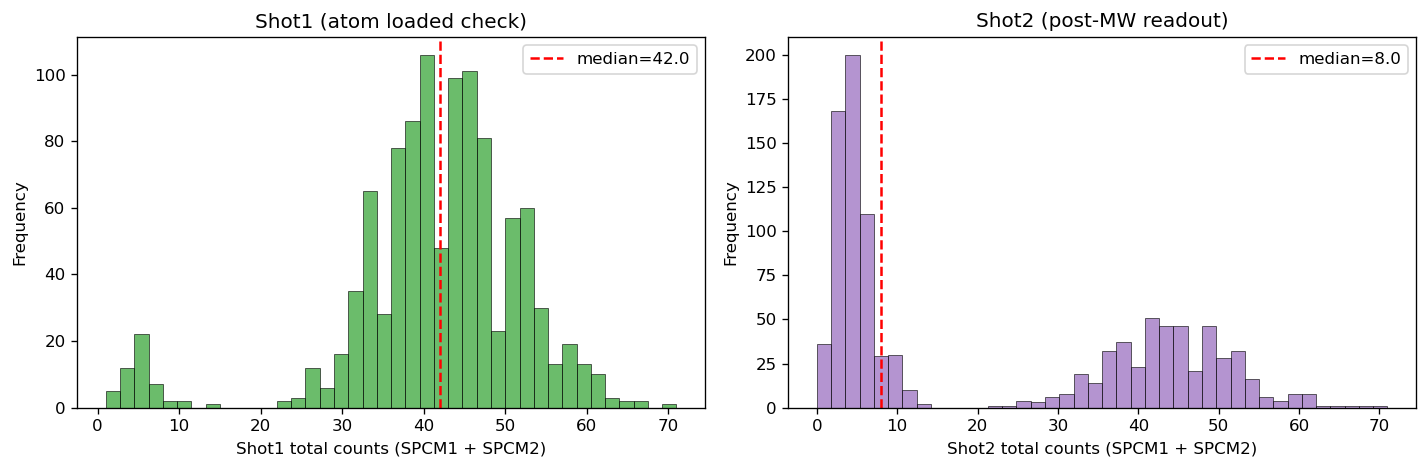

Shot1: min=1 max=71 mean=41.3 median=42.0
Shot2: min=0 max=71 mean=22.1 median=8.0


In [110]:
# Histogram of total SPCM counts for shot1 and shot2
shot1_total = np.asarray(data["mw_shot1_spcm1"], dtype=float) + np.asarray(data["mw_shot1_spcm2"], dtype=float)
shot2_total = np.asarray(data["mw_shot2_spcm1"], dtype=float) + np.asarray(data["mw_shot2_spcm2"], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(shot1_total, bins=40, color="C2", alpha=0.7, edgecolor="black", lw=0.5)
axes[0].set_xlabel("Shot1 total counts (SPCM1 + SPCM2)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Shot1 (atom loaded check)")
axes[0].axvline(np.median(shot1_total), color="red", ls="--", label="median={:.1f}".format(np.median(shot1_total)))
axes[0].legend()

axes[1].hist(shot2_total, bins=40, color="C4", alpha=0.7, edgecolor="black", lw=0.5)
axes[1].set_xlabel("Shot2 total counts (SPCM1 + SPCM2)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Shot2 (post-MW readout)")
axes[1].axvline(np.median(shot2_total), color="red", ls="--", label="median={:.1f}".format(np.median(shot2_total)))
axes[1].legend()

plt.tight_layout()
plt.show()

print("Shot1: min={:.0f} max={:.0f} mean={:.1f} median={:.1f}".format(
    shot1_total.min(), shot1_total.max(), shot1_total.mean(), np.median(shot1_total)))
print("Shot2: min={:.0f} max={:.0f} mean={:.1f} median={:.1f}".format(
    shot2_total.min(), shot2_total.max(), shot2_total.mean(), np.median(shot2_total)))


## 3c. Set Manual Threshold
Set threshold below based on the histograms. This overrides the experiment threshold.


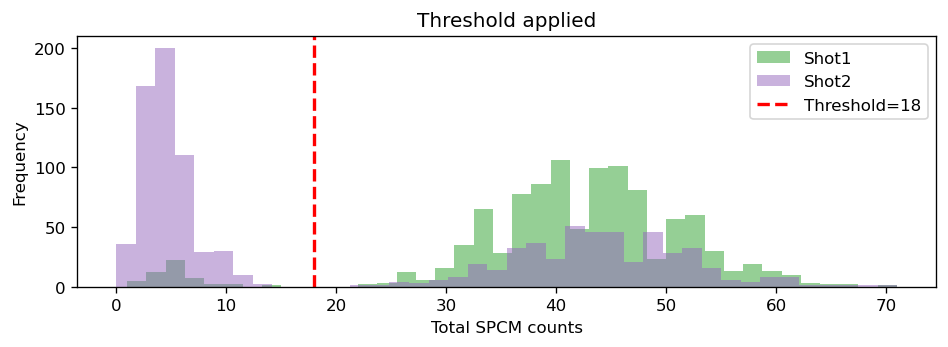

Threshold = 18
Loading rate: 95.1%
Valid scan points: 21 / 21


In [111]:
########################################
THRESHOLD = 18   # <-- set manually from histogram valley
########################################

# Recompute loaded/retained from raw counts using manual threshold
shot1_total = np.asarray(data["mw_shot1_spcm1"], dtype=float) + np.asarray(data["mw_shot1_spcm2"], dtype=float)
shot2_total = np.asarray(data["mw_shot2_spcm1"], dtype=float) + np.asarray(data["mw_shot2_spcm2"], dtype=float)

loaded_raw = (shot1_total > THRESHOLD).astype(float)
retained_raw = (shot2_total > THRESHOLD).astype(float)

# Recompute per-scan-point retention = N(s1>t & s2>t) / N(s1>t)
ret = np.zeros(len(unique_x))
err = np.zeros(len(unique_x))
n_loaded_per = np.zeros(len(unique_x), dtype=int)
for i_pt, xv in enumerate(unique_x):
    mask = x_raw == xv
    l = loaded_raw[mask]
    r = retained_raw[mask]
    n_loaded = int(l.sum())
    n_retained = int((l * r).sum())
    n_loaded_per[i_pt] = n_loaded
    if n_loaded > 0:
        ret[i_pt] = n_retained / n_loaded
        err[i_pt] = np.sqrt(max(ret[i_pt]*(1-ret[i_pt]), 0) / n_loaded)
    else:
        ret[i_pt] = float("nan")
        err[i_pt] = float("nan")

load_rate = np.array([loaded_raw[x_raw == xv].mean() for xv in unique_x])

# Show histogram with threshold line
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(shot1_total, bins=40, color="C2", alpha=0.5, label="Shot1")
ax.hist(shot2_total, bins=40, color="C4", alpha=0.5, label="Shot2")
ax.axvline(THRESHOLD, color="red", lw=2, ls="--", label="Threshold={:.0f}".format(THRESHOLD))
ax.set_xlabel("Total SPCM counts")
ax.set_ylabel("Frequency")
ax.legend()
ax.set_title("Threshold applied")
plt.tight_layout()
plt.show()

print("Threshold = {:.0f}".format(THRESHOLD))
print("Loading rate: {:.1f}%".format(100 * loaded_raw.mean()))
n_valid = sum(~np.isnan(ret))
print("Valid scan points: {} / {}".format(n_valid, len(unique_x)))


## 4. Plot Retention + Counts
Re-run this cell to refresh after more data is collected (incremental saves).

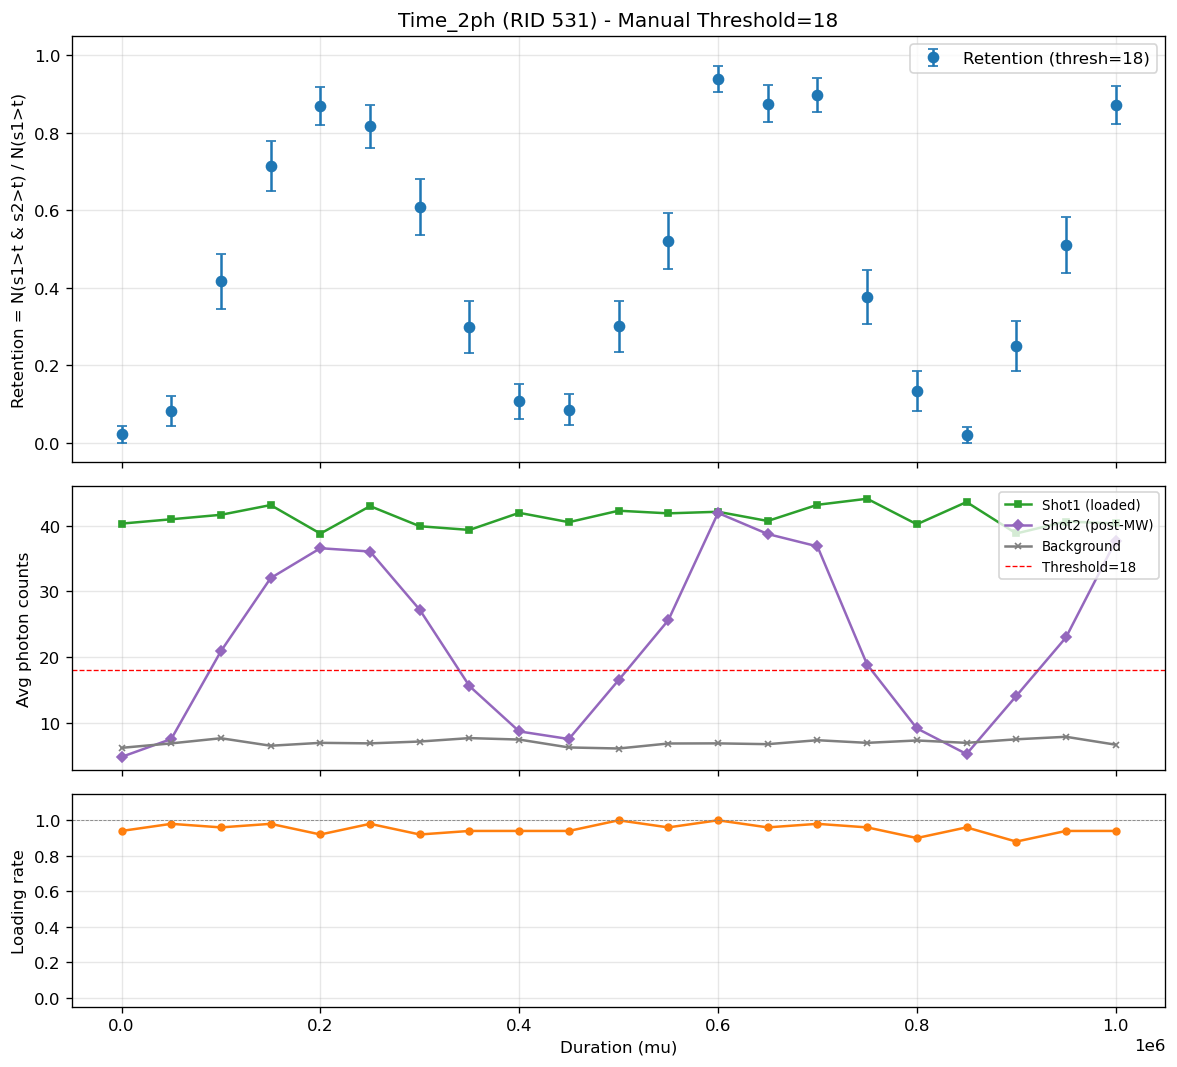

Total: 1050 shots, 50 loops, Threshold=18


In [112]:
# Uses ret, err, load_rate, loaded_raw, retained_raw from threshold cell above
# Re-read data for counts plot only
result = load_h5(filepath)
data = result["data"]
x_raw = np.asarray(data["mw_scan_x"], dtype=float)
unique_x = np.unique(x_raw)

def avg_by_x(key):
    if key not in data: return None
    arr = np.asarray(data[key], dtype=float)
    return np.array([np.mean(arr[x_raw == xv]) for xv in unique_x]) if arr.size == x_raw.size else None

stype = data.get("mw_scan_type", b"frequency")
if isinstance(stype, bytes): stype = stype.decode()
mode = data.get("mw_scan_mode", b"MW Scan")
if isinstance(mode, bytes): mode = mode.decode()

if stype == "frequency":
    if mode == "Freq_2ph":
        # scan_val is the absolute RF antenna freq in Hz; show the small
        # detuning from the 2ph nominal in kHz instead -- much easier to read.
        f00_hz = _scalar(data.get("snapshot_f_mw_00"), default=250.0e6)
        f01_hz = _scalar(data.get("snapshot_f_mw_01"), default=250.468e6)
        rf_detune_khz = _scalar(data.get("snapshot_rf_detune_khz"), default=-125.0)
        base_hz = f01_hz - f00_hz - rf_detune_khz * 1000.0
        xp = (unique_x - base_hz) / 1000.0   # Hz -> kHz detuning
        xlabel = "RF small detuning (kHz)"
    else:
        xp = unique_x / 1e6
        xlabel = "Frequency (MHz)"
else:
    xp = unique_x
    xlabel = "Duration (mu)" if stype == "time" else "Free evolution (mu)"

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                         gridspec_kw={"height_ratios": [3, 2, 1.5]})

ax1 = axes[0]
valid_mask = ~np.isnan(ret)
if valid_mask.any():
    ax1.errorbar(xp[valid_mask], ret[valid_mask], yerr=err[valid_mask],
                 fmt="o", color="C0", capsize=3, markersize=6, label="Retention (thresh={})".format(THRESHOLD))
ax1.set_ylabel("Retention = N(s1>t & s2>t) / N(s1>t)")
ax1.set_ylim(-0.05, 1.05)
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)
ax1.set_title("{} (RID {}) - Manual Threshold={}".format(mode, run_rid, THRESHOLD))

ax2 = axes[1]
s1 = avg_by_x("mw_shot1_spcm1"); s2 = avg_by_x("mw_shot1_spcm2")
p1 = avg_by_x("mw_shot2_spcm1"); p2 = avg_by_x("mw_shot2_spcm2")
b1 = avg_by_x("mw_bg_spcm1");    b2 = avg_by_x("mw_bg_spcm2")
if s1 is not None and s2 is not None:
    ax2.plot(xp, s1+s2, "s-", color="C2", ms=4, label="Shot1 (loaded)")
if p1 is not None and p2 is not None:
    ax2.plot(xp, p1+p2, "D-", color="C4", ms=4, label="Shot2 (post-MW)")
if b1 is not None and b2 is not None:
    ax2.plot(xp, b1+b2, "x-", color="C7", ms=4, label="Background")
ax2.axhline(THRESHOLD, color="red", ls="--", lw=0.8, label="Threshold={}".format(THRESHOLD))
ax2.set_ylabel("Avg photon counts")
ax2.legend(fontsize=8, loc="upper right")
ax2.grid(True, alpha=0.3)

ax3 = axes[2]
if load_rate is not None:
    ax3.plot(xp, load_rate, "o-", color="C1", ms=4)
    ax3.axhline(1.0, color="gray", ls="--", lw=0.5)
ax3.set_ylabel("Loading rate")
ax3.set_ylim(-0.05, 1.15)
ax3.set_xlabel(xlabel)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("Total: {} shots, {} loops, Threshold={}".format(len(x_raw), len(x_raw)//max(len(unique_x),1), THRESHOLD))


## 5. LSQ Fit (v2: global optimizer)

Weighted periodogram frequency seed + multi-seed `differential_evolution` +
`curve_fit` polish (Gauss-Newton covariance). Applies to all scan types:

- **Frequency** -> `GaussianDipFit`: plain LSQ (Gaussian shape, no aliasing)
- **Time (Rabi)** -> `RabiFit`: 5-param model [A, f, phi, tau, y0]; x in ms
- **Ramsey** -> `RamseyFit`: 6-param model [A, f, phi, tau, y0, n]; x in ms

Flags reported: low R2 / at bound / tau unconstrained / no covariance.

Fitter: RabiFit  (5 params, v2 global)
  Periodogram f0 seed: 2.416080 kHz
  bounds_lo:  [0.0, 1.61072, -3.14159, 0.05, 0.0]
  bounds_hi:  [1.0, 3.62412, 3.14159, 100.0, 1.0]

FIT SUCCEEDED  (R² = 0.9681)
  A      = 0.469847  ± 0.01896
  f      = 2.40275  ± 0.02041
  phi    = 2.96794  ± 0.07785
  tau    = 100  ± 656.9
  y0     = 0.494706  ± 0.0104
  FLAGS: at bound: tau; tau unconstrained

  Frequency:  2.402747 kHz  ± 0.02041 kHz
  Pi time:    0.2081 ms = 208095 mu


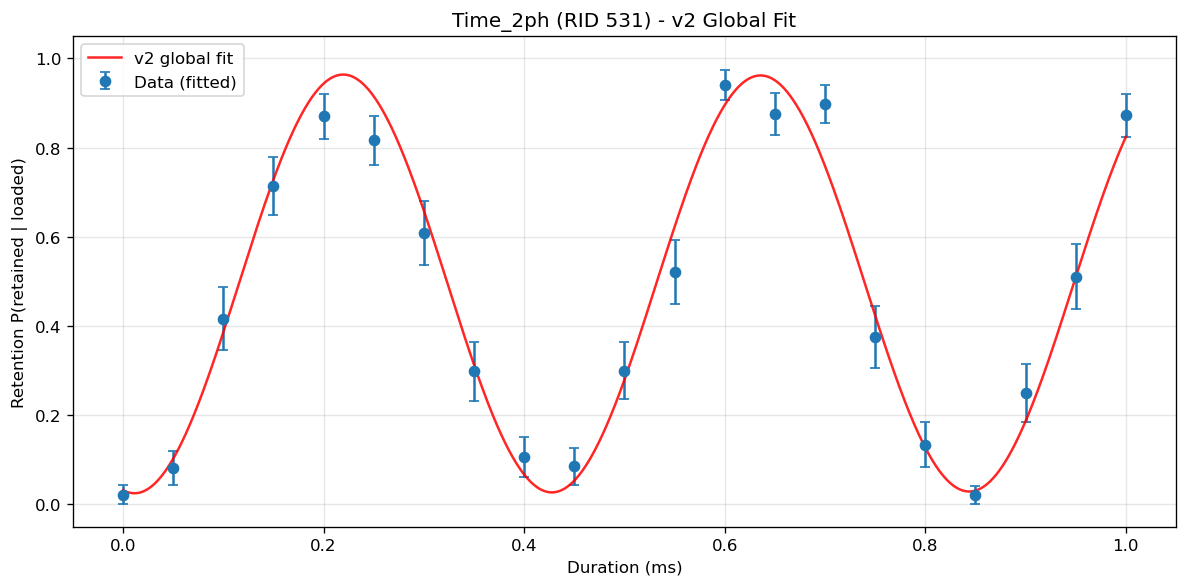

In [113]:
########################################
EXCLUDE_LEFT = 0    # number of points to exclude from the left edge
EXCLUDE_RIGHT = 0   # number of points to exclude from the right edge
########################################

# v2 helpers: weighted floating-mean periodogram for frequency seed,
# and multi-seed differential_evolution -> curve_fit polish.
from scipy.optimize import differential_evolution, curve_fit

def _periodogram_f0(x, y, e):
    """Robust fringe-frequency seed via weighted floating-mean periodogram.

    At each trial frequency f, the model a*cos + b*sin + c is linear, so its
    residual is closed-form. The grid spans [~0.2/span, within-segment Nyquist].
    Among local minima within 10% of the global-best residual, the LOWEST f is
    returned (the Ramsey fringe is the small deliberate detuning; higher near-ties
    are aliases).
    """
    x = np.asarray(x, float); y = np.asarray(y, float); e = np.asarray(e, float)
    w = 1.0 / np.where(e > 0, e, 1.0)
    span = float(x.max() - x.min()) or 1.0
    d = np.diff(np.unique(x)); d = d[d > 0]
    min_step = float(np.min(d)) if len(d) else span
    f_lo, f_hi = 0.2 / span, 0.5 / min_step
    if f_hi <= f_lo: f_hi = f_lo * 10.0
    n_grid = min(max(int((f_hi - f_lo) / (0.3 / span)) + 1, 200), 6000)
    grid = np.linspace(f_lo, f_hi, n_grid)
    yw = y * w; ones = np.ones_like(x)
    resid = np.empty(len(grid))
    for i, f in enumerate(grid):
        M = np.stack([np.cos(2 * np.pi * f * x),
                      np.sin(2 * np.pi * f * x), ones], axis=1) * w[:, None]
        c, _, _, _ = np.linalg.lstsq(M, yw, rcond=None)
        r = yw - M @ c
        resid[i] = float(np.dot(r, r))
    rmin = resid.min()
    is_min = np.r_[True, resid[1:] < resid[:-1]] & np.r_[resid[:-1] < resid[1:], True]
    cand = np.where(is_min & (resid <= rmin * 1.10))[0]
    return float(grid[cand[0]]) if len(cand) else float(grid[int(np.argmin(resid))])


def _fit_global(model_fn, x, y, e, lo, hi, n_params):
    """Multi-seed differential_evolution -> curve_fit polish.

    3 DE seeds (0,1,2); best solution seeds curve_fit for pcov -> perr.
    Falls back to DE solution with perr=inf if curve_fit raises.
    Returns (popt, perr).
    """
    x = np.asarray(x, float); y = np.asarray(y, float)
    e = np.asarray(e, float).copy(); e[e <= 0] = 0.01

    def wssr(p):
        r = (y - model_fn(x, *p)) / e
        return float(np.sum(r * r))

    best = None
    for sd in (0, 1, 2):
        de = differential_evolution(wssr, bounds=list(zip(lo, hi)), seed=sd,
                                    tol=1e-7, maxiter=1000, popsize=25, polish=True)
        if best is None or de.fun < best.fun:
            best = de
    try:
        popt, pcov = curve_fit(model_fn, x, y, p0=best.x, sigma=e,
                               absolute_sigma=True, bounds=(lo, hi), maxfev=40000)
        perr = np.sqrt(np.abs(np.diag(pcov)))
    except Exception:
        popt, perr = np.asarray(best.x), np.full(n_params, np.inf)
    return popt, perr


fit_result = None
fitter = None
valid = ~np.isnan(ret)

# Exclude edge points
valid_indices = np.where(valid)[0]
if EXCLUDE_LEFT > 0 and len(valid_indices) > EXCLUDE_LEFT:
    for idx in valid_indices[:EXCLUDE_LEFT]:
        valid[idx] = False
if EXCLUDE_RIGHT > 0 and len(valid_indices) > EXCLUDE_RIGHT:
    for idx in valid_indices[-EXCLUDE_RIGHT:]:
        valid[idx] = False
if EXCLUDE_LEFT > 0 or EXCLUDE_RIGHT > 0:
    print(f"Excluded {EXCLUDE_LEFT} left + {EXCLUDE_RIGHT} right -> {valid.sum()} points for fit")

import importlib, fitting.gaussian_dip, fitting.damped_cosine
importlib.reload(fitting.gaussian_dip)
importlib.reload(fitting.damped_cosine)

if stype == "frequency":
    from fitting.gaussian_dip import GaussianDipFit
    if mode in ("Freq_11", "Freq_2ph"):
        fitter = GaussianDipFit(direction="peak")
    elif mode in ("Freq_00", "Freq_01"):
        fitter = GaussianDipFit(direction="dip")
    else:
        fitter = GaussianDipFit(direction="auto")
    if mode == "Freq_2ph":
        f00_hz = _scalar(data.get("snapshot_f_mw_00"), default=250.0e6)
        f01_hz = _scalar(data.get("snapshot_f_mw_01"), default=250.468e6)
        rf_detune_khz = _scalar(data.get("snapshot_rf_detune_khz"), default=-125.0)
        base_hz = f01_hz - f00_hz - rf_detune_khz * 1000.0
        x_fit = (unique_x[valid] - base_hz) / 1000.0   # Hz -> kHz
        x_plot = xp
        fit_xlabel = "RF small detuning (kHz)"
        freq_unit = "kHz"
    else:
        x_fit = unique_x[valid] / 1e6   # Hz -> MHz
        x_plot = xp
        fit_xlabel = "Frequency (MHz)"
        freq_unit = "MHz"
elif stype == "ramsey":
    from fitting.damped_cosine import RamseyFit
    fitter = RamseyFit()
    x_fit = unique_x[valid] / 1e6   # mu -> ms
    x_plot = xp / 1e6               # mu -> ms for plotting
    fit_xlabel = "Free evolution time (ms)"
elif stype == "time":
    from fitting.damped_cosine import RabiFit
    fitter = RabiFit()
    x_fit = unique_x[valid] / 1e6   # mu -> ms
    x_plot = xp / 1e6               # mu -> ms for plotting
    fit_xlabel = "Duration (ms)"
else:
    x_fit = unique_x[valid].astype(float)
    x_plot = xp
    fit_xlabel = xlabel
    print(f"No fitter for scan type '{stype}'")

if fitter is not None and valid.sum() >= 4:
    ret_fit = ret[valid]
    err_fit = err[valid].copy()
    err_fit[err_fit == 0] = 0.01

    if stype == "frequency":
        # Frequency scans: plain LSQ via fit_lsq (Gaussian shape, no aliasing issue)
        p0, lo, hi = fitter.initial_guess(x_fit, ret_fit, yerr=err_fit)
        print(f"Fitter: {type(fitter).__name__}  ({len(p0)} params)")
        print(f"  p0 :        {[round(v, 5) for v in p0]}")
        print(f"  bounds_lo:  {[round(v, 5) for v in lo]}")
        print(f"  bounds_hi:  {[round(v, 5) for v in hi]}")
        fit_lsq_result = fitter.fit_lsq(x_fit, ret_fit, yerr=err_fit, p0=p0, bounds=(lo, hi))
        if fit_lsq_result["success"]:
            fit_result = fit_lsq_result
        else:
            fit_result = fit_lsq_result

    else:
        # Time (Rabi) and Ramsey: v2 global optimizer
        span_fit = float(x_fit.max() - x_fit.min()) or 1.0
        f0 = _periodogram_f0(x_fit, ret_fit, err_fit)
        n_params = 5 if stype == "time" else 6
        lo = [0.0, max(1e-4, f0 / 1.5), -np.pi, 0.05 * span_fit, 0.0]
        hi = [1.0, f0 * 1.5,            np.pi,  100.0 * span_fit, 1.0]
        if stype == "ramsey":
            lo.append(1.0);  hi.append(2.0)   # n free in [1, 2]
        model_fn = RabiFit.model if stype == "time" else RamseyFit.model
        print(f"Fitter: {type(fitter).__name__}  ({n_params} params, v2 global)")
        print(f"  Periodogram f0 seed: {f0:.6f} {'kHz' if stype == 'time' else 'kHz'}")
        print(f"  bounds_lo:  {[round(v, 5) for v in lo]}")
        print(f"  bounds_hi:  {[round(v, 5) for v in hi]}")
        popt, perr = _fit_global(model_fn, x_fit, ret_fit, err_fit, lo, hi, n_params)
        fit_result = {"success": True, "params": popt, "errors": perr}

    if fit_result["success"]:
        params = fit_result["params"]
        errors = fit_result["errors"]
        y_pred = fitter.evaluate(x_fit, params)
        ss_res = np.sum((ret_fit - y_pred) ** 2)
        ss_tot = np.sum((ret_fit - np.mean(ret_fit)) ** 2)
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0

        print(f"\nFIT SUCCEEDED  (R\u00b2 = {r2:.4f})")
        for nm, p, e in zip(fitter.param_names, params, errors):
            e_str = f"{e:.4g}" if np.isfinite(e) else "inf"
            print(f"  {nm:6s} = {p:.6g}  \u00b1 {e_str}")

        # --- Flag checks (same logic as v2 notebook) ---
        if stype != "frequency":
            flags = []
            if r2 < 0.5:
                flags.append("low R2")
            lo_a = np.array(lo); hi_a = np.array(hi)
            railed = ((np.abs(params - lo_a) <= 1e-9 + 0.02 * np.abs(lo_a)) |
                      (np.abs(params - hi_a) <= 1e-9 + 0.02 * np.abs(hi_a)))
            # Exclude 'n' from at-bound check (it legitimately rails at 1 or 2)
            pnames_check = fitter.param_names
            bn = [pnames_check[i] for i in range(len(params))
                  if railed[i] and pnames_check[i] != "n"]
            if bn:
                flags.append("at bound: " + ",".join(bn))
            if len(params) >= 4 and np.isfinite(errors[3]) and params[3] > 0 and errors[3] > params[3]:
                flags.append("tau unconstrained")
            if not np.all(np.isfinite(errors)):
                flags.append("no covariance")
            if flags:
                print(f"  FLAGS: {'; '.join(flags)}")
            else:
                print("  Flags: none")

        # Type-specific derived quantities
        if stype == "frequency":
            center, center_err = fitter.center(fit_result)
            fwhm, fwhm_err = fitter.fwhm(fit_result)
            print(f"\n  Resonance: {center:.6f} \u00b1 {center_err:.6f} {freq_unit}")
            print(f"  FWHM:      {fwhm:.6f} \u00b1 {fwhm_err:.6f} {freq_unit}")
        elif stype == "ramsey":
            f_khz, f_err = fitter.frequency_khz(fit_result)
            tau_ms, tau_err = fitter.decay_time_ms(fit_result)
            n_exp, n_err = fitter.decay_exponent(fit_result)
            vis, vis_err = fitter.visibility(fit_result)
            tau_err_str = f"{tau_err:.2f}" if np.isfinite(tau_err) else "inf"
            print(f"\n  Frequency:  {f_khz:.4f} \u00b1 {f_err:.4f} kHz")
            print(f"  Tau:        {tau_ms:.2f} \u00b1 {tau_err_str} ms")
            print(f"  Exponent n: {n_exp:.3f} \u00b1 {n_err:.3f}")
            print(f"  Visibility: {vis:.3f} \u00b1 {vis_err:.3f}")
        elif stype == "time":
            f_khz = params[1]   # x_fit is in ms, so f is in kHz
            t_pi_ms = 0.5 / f_khz if f_khz > 0 else float('inf')
            t_pi_mu = t_pi_ms * 1e6
            f_err_str = f"{errors[1]:.4g}" if np.isfinite(errors[1]) else "inf"
            print(f"\n  Frequency:  {f_khz:.6f} kHz  \u00b1 {f_err_str} kHz")
            print(f"  Pi time:    {t_pi_ms:.4f} ms = {t_pi_mu:.0f} mu")
    else:
        print("\nFIT FAILED")
elif fitter is not None:
    print(f"Cannot fit: {valid.sum()} valid points (need >= 4)")

# --- Plot data + fit overlay ---
fig, ax = plt.subplots(figsize=(10, 5))
all_valid = ~np.isnan(ret)
excluded = all_valid & ~valid

if all_valid.any():
    ax.errorbar(x_plot[valid], ret[valid], yerr=err[valid], fmt="o", color="C0",
                capsize=3, ms=6, label="Data (fitted)")
    if excluded.any():
        ax.errorbar(x_plot[excluded], ret[excluded], yerr=err[excluded], fmt="o",
                    color="gray", capsize=3, ms=5, alpha=0.4, label="Excluded")

if fit_result is not None and fit_result.get("success") and fitter is not None:
    x_fine = np.linspace(x_plot[all_valid].min(), x_plot[all_valid].max(), 2000)
    y_fine = fitter.evaluate(x_fine, fit_result["params"])
    ax.plot(x_fine, y_fine, "r-", lw=1.5, alpha=0.85, label="v2 global fit")

ax.set_xlabel(fit_xlabel)
ax.set_ylabel("Retention P(retained | loaded)")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"{mode} (RID {run_rid}) - v2 Global Fit")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 5b. Ramsey Segment Zoom
Plot each Ramsey segment separately for closer inspection. Auto-detects segments from gaps in the scan axis.

Found 4 segment(s)


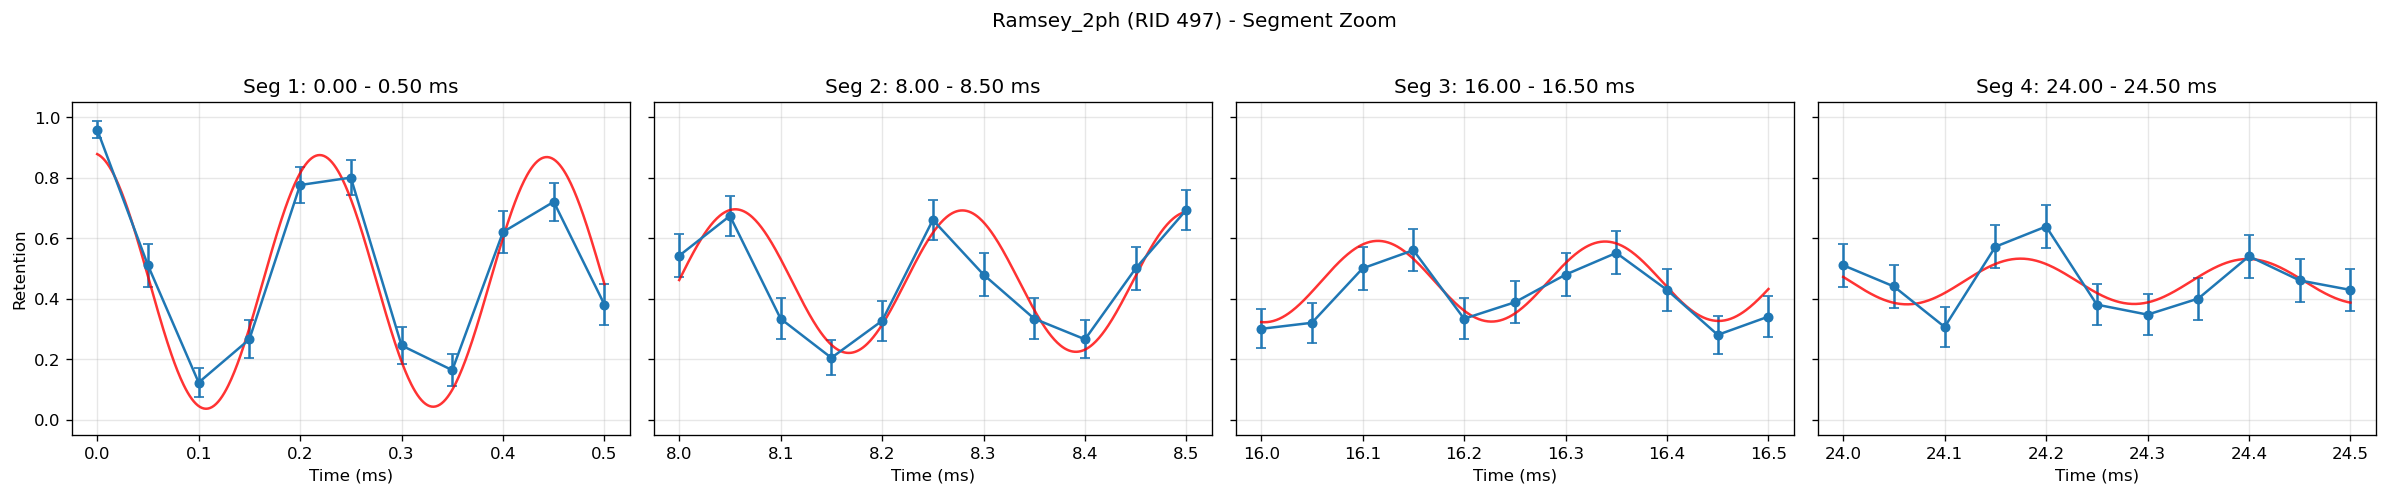

In [9]:
# Auto-detect segments from gaps in scan axis (works for Ramsey multi-segment scans)
valid_mask = ~np.isnan(ret)

# Use ms for Ramsey and time (Rabi), MHz for frequency
# Note: fit_result and fitter.evaluate() now use ms for both ramsey and time.
if stype == "ramsey":
    xv_seg = unique_x[valid_mask] / 1e6  # mu to ms
    seg_unit = "ms"
elif stype == "frequency":
    xv_seg = unique_x[valid_mask] / 1e6  # Hz to MHz
    seg_unit = "MHz"
else:
    xv_seg = unique_x[valid_mask] / 1e6  # mu to ms (Rabi x_fit is also in ms)
    seg_unit = "ms"

rv = ret[valid_mask]
ev = err[valid_mask]

# Find segment boundaries: gap > 2x median step
if len(xv_seg) > 1:
    diffs = np.diff(xv_seg)
    median_step = np.median(diffs)
    gap_indices = np.where(diffs > 2 * median_step)[0]
    seg_starts = np.concatenate([[0], gap_indices + 1])
    seg_ends = np.concatenate([gap_indices + 1, [len(xv_seg)]])
else:
    seg_starts = [0]
    seg_ends = [len(xv_seg)]

n_segs = len(seg_starts)
print("Found %d segment(s)" % n_segs)

if n_segs > 1:
    fig, axes = plt.subplots(1, n_segs, figsize=(5 * n_segs, 4), sharey=True)
    if n_segs == 1:
        axes = [axes]

    for s, (si, ei) in enumerate(zip(seg_starts, seg_ends)):
        ax = axes[s]
        xs = xv_seg[si:ei]
        rs = rv[si:ei]
        es = ev[si:ei]

        ax.errorbar(xs, rs, yerr=es, fmt="o-", color="C0", capsize=3, ms=5)

        # Overlay fit curve if available
        if fit_result and fit_result.get("success") and fitter is not None:
            x_fine_seg = np.linspace(xs[0], xs[-1], 500)
            y_fine_seg = fitter.evaluate(x_fine_seg, fit_result["params"])
            ax.plot(x_fine_seg, y_fine_seg, "r-", lw=1.5, alpha=0.8)

        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel("%s (%s)" % ("Time" if stype != "frequency" else "Freq", seg_unit))
        ax.set_title("Seg %d: %.2f - %.2f %s" % (s+1, xs[0], xs[-1], seg_unit))
        ax.grid(True, alpha=0.3)
        if s == 0:
            ax.set_ylabel("Retention")

    plt.suptitle("%s (RID %s) - Segment Zoom" % (mode, run_rid), y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Only 1 segment - use the main plot above.")


## 6. Browse All Datasets

In [ ]:
print("=== datasets/ ===")
for k in sorted(data.keys()):
    v = data[k]
    if isinstance(v, np.ndarray) and v.size > 0:
        print(f"  {k:40s}  {str(v.dtype):8s}  shape={str(v.shape):12s}  [{v.min():.4g} .. {v.max():.4g}]")
    elif isinstance(v, np.ndarray):
        print(f"  {k:40s}  {str(v.dtype):8s}  shape={str(v.shape):12s}  (empty)")
    else:
        val = v.decode() if isinstance(v, bytes) else v
        print(f"  {k:40s}  = {val}")

print(f"\n=== archive/ ({len(archive)} keys) ===")
for k in sorted(archive.keys())[:20]:
    v = archive[k]
    val = v.decode() if isinstance(v, bytes) else v
    print(f"  {k:40s}  = {val}")
if len(archive) > 20:
    print(f"  ... and {len(archive)-20} more")